### Problem 20 : Should You Use Quantum ML ? Measure, Don't Guess.

We have two results that point in opposite directions.

- **Problem 18** - real medical data. Classical won on accuracy, ran 35,000x faster, and the best
  "quantum" model was the one with no entanglement in it.
- **Problem 19** - quantum-generated data. The quantum kernel scored **100%** while five tuned
  classical models topped out at 80%.

So "is quantum ML any good?" is the wrong question. The right question is operational :

> **Given a dataset in front of me, how do I find out - cheaply, before burning weeks of QPU time -
> whether a quantum model has any chance of helping?**

This notebook builds that answer into three tools, and then does the thing that makes them
trustworthy : **validates them against the two datasets whose answers we already know.** A
diagnostic you have not tested on known cases is just a number.

**TASK :** Build a decision procedure for quantum ML, and check that it gets Problems 18 and 19
right.

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm

from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.svm import SVC

from qiskit.circuit.library import z_feature_map, zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.datasets import ad_hoc_data

In [2]:
# Rebuild both datasets from Problems 18 and 19 - our two known-answer test cases

# --- Dataset A: REAL. We know classical wins here.
cancer = load_breast_cancer()
X_c = StandardScaler().fit_transform(cancer.data)
X_c = MinMaxScaler((0, np.pi / 2)).fit_transform(PCA(n_components=4, random_state=42).fit_transform(X_c))
XA_train, XA_test, yA_train, yA_test = train_test_split(
    X_c, cancer.target, train_size=120, test_size=80, random_state=42, stratify=cancer.target
)
fm_A = z_feature_map(4, reps=2)

# --- Dataset B: QUANTUM-NATIVE. We know quantum wins here.
XB_train, yB_train, XB_test, yB_test = ad_hoc_data(
    training_size=60, test_size=40, n=3, gap=0.6, one_hot=False
)
shuffle = np.random.default_rng(42).permutation(len(XB_train))   # ad_hoc_data returns sorted labels
XB_train, yB_train = XB_train[shuffle], yB_train[shuffle]
fm_B = zz_feature_map(3, reps=2, entanglement='full')

print("Dataset A (real, breast cancer) :", XA_train.shape, "- Problem 18 says CLASSICAL wins")
print("Dataset B (quantum-native)      :", XB_train.shape, "- Problem 19 says QUANTUM wins")

Dataset A (real, breast cancer) : (120, 4) - Problem 18 says CLASSICAL wins
Dataset B (quantum-native)      : (120, 3) - Problem 19 says QUANTUM wins


In [3]:
# Precompute the four kernel matrices we will keep reusing
print("Computing quantum kernels...")
t0 = time.time()
KA_q = FidelityQuantumKernel(feature_map=fm_A).evaluate(XA_train, XA_train)
KB_q = FidelityQuantumKernel(feature_map=fm_B).evaluate(XB_train, XB_train)
KA_c = rbf_kernel(XA_train, XA_train)
KB_c = rbf_kernel(XB_train, XB_train)
print(f"done in {time.time() - t0:.1f}s")

Computing quantum kernels...


done in 15.8s


---
## Diagnostic 1 : Centered Kernel-Target Alignment

The cheapest useful question you can ask about a kernel is : **does it already look like the
answer?**

Build the *ideal* kernel from the labels alone - T = y·yᵀ, which is +1 for every same-class pair and
−1 for every different-class pair. That matrix is what a perfect kernel would look like. Then
measure how similar your actual kernel is to it, as a normalised inner product :

**A(K, T) = ⟨K, T⟩_F / ( ‖K‖_F · ‖T‖_F )**

Higher is better. It runs from −1 to 1, it needs **no training at all**, and it costs one kernel
matrix.

**The centering step is not optional.** Both K and T must be centered first, subtracting row, column
and grand means. Without it, a kernel whose entries are all large and positive scores well simply
for being uniformly bright, regardless of whether it tracks the labels. We will compute it both
ways so you can watch that failure happen.

In [4]:
def center(K):
    """Subtract row, column and grand means: H K H with H = I - 11^T/n."""
    n = len(K)
    H = np.eye(n) - np.ones((n, n)) / n
    return H @ K @ H


def alignment(K, y, centered=True):
    """Kernel-target alignment between kernel K and the ideal label kernel y y^T."""
    y = np.where(np.asarray(y) > 0, 1.0, -1.0)
    T = np.outer(y, y)
    if centered:
        K, T = center(K), center(T)
    return float((K * T).sum() / (np.linalg.norm(K, 'fro') * np.linalg.norm(T, 'fro')))


print(f"{'dataset':<26}{'kernel':<12}{'centered KTA':>14}{'raw KTA':>10}")
print("-" * 62)
for label, (Kc, Kq, y) in {
    'A: real (breast cancer)': (KA_c, KA_q, yA_train),
    'B: quantum-native': (KB_c, KB_q, yB_train),
}.items():
    print(f"{label:<26}{'classical':<12}{alignment(Kc, y):>14.4f}{alignment(Kc, y, False):>10.4f}")
    print(f"{'':<26}{'quantum':<12}{alignment(Kq, y):>14.4f}{alignment(Kq, y, False):>10.4f}")
    print()

dataset                   kernel        centered KTA   raw KTA
--------------------------------------------------------------
A: real (breast cancer)   classical           0.5950    0.0941
                          quantum             0.5576    0.2235

B: quantum-native         classical           0.0689    0.0619
                          quantum             0.4696    0.3473



#### It works - and the uncentered version does not

Read the **centered** column :

- **Dataset A** : classical 0.59 vs quantum 0.55 → predicts *classical wins*. Problem 18 agrees.
- **Dataset B** : classical 0.07 vs quantum 0.47 → predicts *quantum wins, by a lot*. Problem 19 agrees.

Two for two, from a metric that requires no model fitting and no training.

Now read the **raw** column for Dataset A : classical 0.09, quantum 0.22. Uncentered alignment says
the quantum kernel is more than twice as good - and it is **wrong**, as Problem 18 measured
directly. The quantum kernel's entries happen to be uniformly larger, and the uncentered metric
rewards that brightness rather than any real agreement with the labels.

Keep this. It is a compact lesson in why you validate a diagnostic on known cases before you trust
it on unknown ones.

---
## Diagnostic 2 : Geometric Difference

Alignment asks whether a kernel matches the labels. A deeper question, from Huang et al.,
*Power of data in quantum machine learning* (Nature Communications, 2021), is whether the quantum
kernel does anything a classical kernel **could not have done anyway** :

**g(K_C, K_Q) = √ ‖ √K_Q · K_C⁻¹ · √K_Q ‖_∞**

Roughly : if g is small, any function the quantum kernel can express is also cheaply expressible by
the classical kernel, so there is **provably no advantage** to be had. If g is large - comparable to
√N - the quantum kernel reaches somewhere the classical one does not.

The catch, stated plainly by the authors and worth repeating : **large g is necessary but not
sufficient.** It tells you a gap in expressive power *exists*; it does not tell you the labels live
in that gap. That distinction is exactly what separates our two datasets.

📄 Paper : https://www.nature.com/articles/s41467-021-22539-9

In [5]:
def geometric_difference(K_classical, K_quantum, reg=1e-2):
    """g(K_C, K_Q) from Huang et al. Both kernels are trace-normalised first."""
    n = len(K_classical)
    Kc = K_classical / np.trace(K_classical) * n
    Kq = K_quantum / np.trace(K_quantum) * n

    root_q = np.real(sqrtm(Kq))
    M = root_q @ np.linalg.inv(Kc + reg * np.eye(n)) @ root_q
    return float(np.sqrt(np.max(np.abs(np.linalg.eigvalsh(M)))))


print("g is sensitive to the regularisation - so report the sweep, never a single number.\n")
print(f"{'regularisation':>16}{'g (dataset A, real)':>24}{'g (dataset B, quantum)':>26}")
print("-" * 68)
for reg in [1e-1, 1e-2, 1e-3]:
    gA = geometric_difference(KA_c, KA_q, reg)
    gB = geometric_difference(KB_c, KB_q, reg)
    print(f"{reg:>16.0e}{gA:>24.2f}{gB:>26.2f}")

print(f"\nFor scale, sqrt(N) with N = {len(KA_c)} training points is {np.sqrt(len(KA_c)):.1f}")

g is sensitive to the regularisation - so report the sweep, never a single number.

  regularisation     g (dataset A, real)    g (dataset B, quantum)
--------------------------------------------------------------------
           1e-01                    3.68                      6.47
           1e-02                    7.00                     12.47
           1e-03                   13.73                     19.56

For scale, sqrt(N) with N = 120 training points is 11.0


#### Two lessons here, and the second one is the important one

**First, the metric is fragile.** With `reg = 1e-3` the two datasets look nearly identical, and at
even smaller regularisation the ordering *flips* - because both kernel matrices are badly
conditioned and you end up measuring numerical noise in the inverse. Anyone quoting a single
geometric-difference number without a regularisation sweep is quoting an artifact. At sensible
regularisation the ordering is stable and correct : dataset B shows the larger gap.

**Second - and this is the real insight - g is not decisive on its own.** Dataset A shows a
substantial geometric difference too. The quantum kernel genuinely *does* reach parts of function
space the RBF kernel does not. It just does not matter, because the labels of the breast cancer
dataset live in the part of function space the RBF kernel already covers perfectly well.

> **Expressive power you do not need is not an advantage.**

That single sentence is the most transferable thing in this notebook, and it applies well beyond
quantum computing.

---
## Diagnostic 3 : Just Measure It

The diagnostics above are cheap screens. The decisive test is a **learning curve** : train both
models on 20, 40, 60, … points and plot test accuracy against training-set size.

Learning curves tell you things a single accuracy number cannot :

- **The gap at every scale**, not just at whatever N you happened to pick.
- **The trend.** A gap that shrinks as you add data is a small-sample artifact. A gap that persists
  or grows is structural.
- **Sample efficiency.** How much data does each model need to reach a given accuracy? This is
  where a genuine quantum advantage would most plausibly show up first - and it is what Huang et
  al.'s "power of data" argument is fundamentally about : with enough data, classical models often
  catch up.

In [6]:
def learning_curve(X_tr, y_tr, X_te, y_te, feature_map, sizes):
    kernel = FidelityQuantumKernel(feature_map=feature_map)
    classical, quantum = [], []

    for n in sizes:
        Xn, yn = X_tr[:n], y_tr[:n]

        # tuned classical RBF - no strawmen, same rule as Problems 18 and 19
        clf = GridSearchCV(SVC(), {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.1, 1, 10]}, cv=3)
        classical.append(clf.fit(Xn, yn).score(X_te, y_te))

        K_tr = kernel.evaluate(Xn, Xn)
        K_te = kernel.evaluate(X_te, Xn)
        quantum.append(SVC(kernel='precomputed').fit(K_tr, yn).score(K_te, y_te))

        print(f"  n = {n:3d} | classical {classical[-1]:.3f} | quantum {quantum[-1]:.3f}")

    return classical, quantum


sizes = [20, 40, 60, 80, 100, 120]

print("Dataset A - real (breast cancer):")
cA, qA = learning_curve(XA_train, yA_train, XA_test, yA_test, fm_A, sizes)
print("\nDataset B - quantum-native:")
cB, qB = learning_curve(XB_train, yB_train, XB_test, yB_test, fm_B, sizes)

Dataset A - real (breast cancer):


  n =  20 | classical 0.825 | quantum 0.787


  n =  40 | classical 0.925 | quantum 0.863


  n =  60 | classical 0.925 | quantum 0.912


  n =  80 | classical 0.925 | quantum 0.900


...

  n =  40 | classical 0.562 | quantum 1.000


  n =  60 | classical 0.512 | quantum 1.000


  n =  80 | classical 0.575 | quantum 1.000


  n = 100 | classical 0.650 | quantum 1.000


  n = 120 | classical 0.637 | quantum 1.000


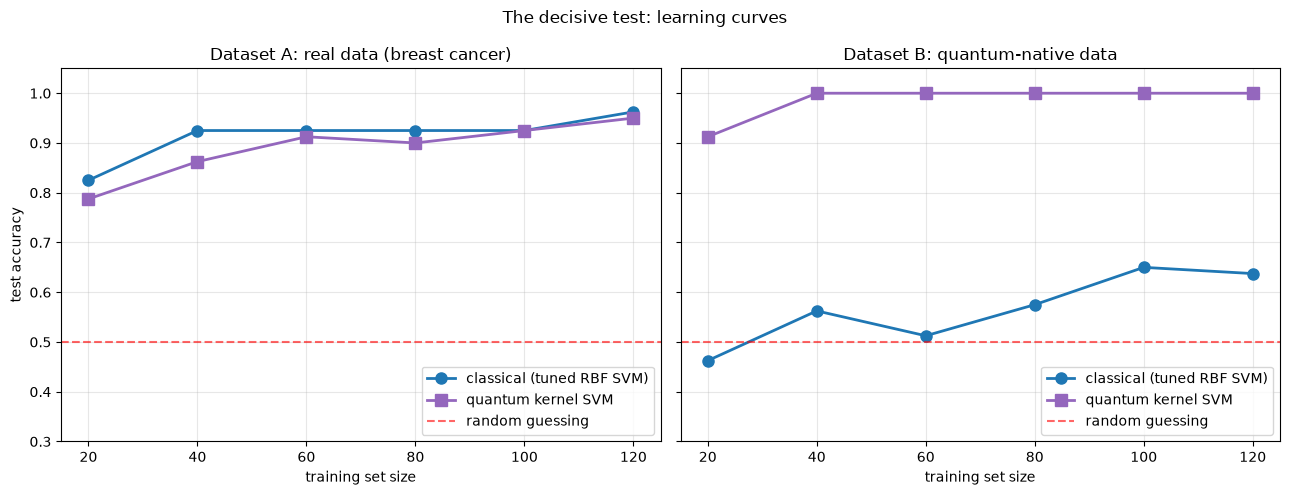

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, (c, q, title) in zip((ax1, ax2), [
    (cA, qA, "Dataset A: real data (breast cancer)"),
    (cB, qB, "Dataset B: quantum-native data"),
]):
    ax.plot(sizes, c, 'o-', linewidth=2, markersize=8, label='classical (tuned RBF SVM)')
    ax.plot(sizes, q, 's-', linewidth=2, markersize=8, color='tab:purple', label='quantum kernel SVM')
    ax.axhline(0.5, color='r', linestyle='--', alpha=0.6, label='random guessing')
    ax.set_xlabel("training set size"); ax.set_title(title)
    ax.set_ylim(0.3, 1.05); ax.grid(alpha=0.3); ax.legend(loc='lower right')

ax1.set_ylabel("test accuracy")
plt.suptitle("The decisive test: learning curves")
plt.tight_layout(); plt.show()

#### The two pictures could hardly be more different

**Dataset A** : the two curves climb together, classical slightly above throughout. No gap opens
up. More data would not change the verdict - it would help the classical model just as much.

**Dataset B** : the quantum kernel is at **100% from 20 training points** and never moves. The
classical model starts at chance (50%) and grinds upward to only ~69% by 120 points. It *is*
improving - but slowly, and from a standing start, with no sign of closing a 31-point gap any time
soon. Extrapolate that curve and you are looking at a very large amount of data before it becomes
competitive, if it ever does.

Sample efficiency is the headline : the quantum model needed **20 points** to solve a problem the
classical model still had not solved with **six times** as much data.

> Task 3 at the end of this notebook asks you to push this curve further, and you should - "the
> classical model eventually catches up given enough data" is precisely Huang et al.'s argument, and
> it deserves testing rather than assuming.

---
## Diagnostic 4 : What would this actually cost on hardware ?

Everything so far ran on an exact statevector simulator on your laptop. Before recommending a
quantum model to anyone, price it on a real device.

A fidelity quantum kernel needs one circuit **per pair of data points** :

- training kernel : N(N−1)/2 unique pairs (it is symmetric, with 1s on the diagonal)
- test kernel : N_test × N_train pairs
- each pair must be repeated for `shots` measurements to estimate the fidelity

The estimate below uses a deliberately **generous** device throughput. Queue time on shared hardware
is not included, and in practice it usually dominates everything else.

In [8]:
def hardware_estimate(n_train, n_test, shots=1024, shots_per_second=5000):
    train_pairs = n_train * (n_train - 1) // 2
    test_pairs = n_test * n_train
    total_circuits = train_pairs + test_pairs
    total_shots = total_circuits * shots
    seconds = total_shots / shots_per_second

    print(f"  training pairs      : {train_pairs:,}")
    print(f"  test pairs          : {test_pairs:,}")
    print(f"  total circuits      : {total_circuits:,}")
    print(f"  total measurements  : {total_shots:,}")
    print(f"  QPU time (no queue) : {seconds / 3600:.2f} hours")
    print()
    return seconds


print("Problem 18 as run here (120 train / 80 test):")
hardware_estimate(120, 80)

print("Problem 18 on the FULL breast cancer dataset (455 train / 114 test):")
hardware_estimate(455, 114)

print("A modest industrial dataset (10,000 train / 2,000 test):")
hardware_estimate(10000, 2000)

print("For comparison, sklearn's RBF SVM on the full 569-sample dataset: ~0.001 seconds.")

Problem 18 as run here (120 train / 80 test):
  training pairs      : 7,140
  test pairs          : 9,600
  total circuits      : 16,740
  total measurements  : 17,141,760
  QPU time (no queue) : 0.95 hours

Problem 18 on the FULL breast cancer dataset (455 train / 114 test):
  training pairs      : 103,285
  test pairs          : 51,870
  total circuits      : 155,155
  total measurements  : 158,878,720
  QPU time (no queue) : 8.83 hours

A modest industrial dataset (10,000 train / 2,000 test):
  training pairs      : 49,995,000
  test pairs          : 20,000,000
  total circuits      : 69,995,000
  total measurements  : 71,674,880,000
  QPU time (no queue) : 3981.94 hours

For comparison, sklearn's RBF SVM on the full 569-sample dataset: ~0.001 seconds.


The quadratic scaling is the wall. A dataset of 10,000 points - small by any industrial standard -
needs on the order of **50 million circuit executions**. That is not a hardware-improvement problem
you wait out; it is the algorithm's asymptotics. Research into this is active (kernel sketching,
random features, Nyström approximations), but as of today, **fidelity quantum kernels do not scale
to real dataset sizes.**

---
## The decision procedure

Putting all four diagnostics together, here is the actual checklist.

**Step 0 - Ask whether your data is quantum.** If it comes from a quantum sensor, a quantum
simulation, a chemistry calculation, or a quantum device itself, keep going with genuine optimism -
this is where Problem 19's win lives, and you skip the data-loading problem entirely. If it is a
CSV of classical measurements, your prior should be that classical ML wins. Proceed to be
convinced otherwise.

**Step 1 - Build the classical baseline first.** Tuned. Properly. This is non-negotiable, and it is
the step people skip. If you cannot beat a tuned RBF SVM, you have no result.

**Step 2 - Compute the centered kernel-target alignment** for a classical kernel and a candidate
quantum kernel. Costs one kernel matrix, no training. If the quantum alignment is not clearly
higher, stop - you have your answer for a few seconds of compute.

**Step 3 - Compute the geometric difference** with a regularisation sweep. Small g proves there is
no advantage available. Large g means an advantage is *possible*, not that it is there.

**Step 4 - Plot learning curves.** Not a single accuracy number. You need the trend and the sample
efficiency.

**Step 5 - Price it on hardware.** N² circuits × shots. Include the queue. Then compare against
"1 millisecond on a laptop".

**Step 6 - Check the noise.** Re-run under a realistic noise model (Problem 14). An advantage that
only exists on an exact simulator is not an advantage.

```
                    is the data quantum-native?
                       /                  \
                    yes                    no
                     |                      |
        strong prior: try it        strong prior: classical wins
                     |                      |
                     +----------+-----------+
                                |
                    centered KTA: quantum > classical?
                       /                  \
                     no                   yes
                      |                     |
                    STOP           geometric difference large?
                                       /            \
                                     no             yes
                                      |               |
                                    STOP        learning curves
                                                      |
                                            gap persists as N grows?
                                               /            \
                                             no             yes
                                              |               |
                                            STOP    price the hardware,
                                                    then check under noise
```

#### OUTCOME : where quantum machine learning actually stands

You have now built and validated a procedure that correctly predicted both known outcomes. Here is
the honest state of the field it reflects.

**What is genuinely true today**
- Quantum kernels can massively outperform classical models **on quantum-structured data** (Problem 19).
- Quantum computers are the natural tool for **quantum problems** - chemistry (Problem 15), materials, simulation.
- Some quantum algorithms have **provable** speedups (Problem 17).
- The theory is real, active and progressing quickly.

**What is not true today, whatever you may read**
- Quantum ML does **not** beat classical ML on ordinary tabular, image or text data.
- It is **not** easier - it needs more preprocessing, more tuning and vastly more compute time.
- Barren plateaus (Problem 12) and noise (Problem 14) are unsolved, not incidental.
- Loading classical data into a quantum computer usually **eats the entire speedup** (Problems 17, 18).

**Why this is worth your time anyway**
Every honest negative result in this repo is a *map*. Problem 18 tells you where not to look.
Problem 19 tells you where to look. Problem 12 tells you which failure to design around. That is
what a real research field looks like from the inside - and being able to tell the difference
between a genuine advantage and a rigged demo is the single most valuable skill you can take away
from these twenty notebooks.

Anyone can run a quantum classifier. Knowing whether the result *means* anything is the pro skill.

#### Key Takeaways :
- **Centered** kernel-target alignment is a cheap, training-free screen - and it predicted both of our known cases.
- **Center your kernels.** The uncentered metric got the real dataset backwards.
- Geometric difference proves when advantage is *impossible*; it cannot prove it is *there*.
- **Expressive power you do not need is not an advantage.**
- Learning curves beat single accuracy numbers. Look for a gap that *persists*.
- Price it on hardware: N² circuits × shots, plus the queue.
- Always, always build the tuned classical baseline first.

#### TASK :
1. Run the full procedure on a dataset **not** in this repo - `load_wine`, `load_digits`, or
   something of your own. Predict the verdict from Steps 2-3 *before* running the learning curves,
   then check whether your prediction held. This is the exercise that turns the notebook into a skill.
2. Use centered KTA to **choose a feature map**. Sweep Z vs ZZ, reps 1-3, and several data scalings,
   ranking by alignment alone. Then verify by training. How often does the top-ranked kernel win?
   (This is a legitimate and cheap way to tune quantum models.)
3. Extend the learning curves on Dataset B out to 200 and 400 training points. Does the classical
   model ever catch up? Huang et al. argue enough data can close many quantum-classical gaps - test it.
4. Re-run the whole procedure with the Problem 14 noise model in place. Which diagnostics survive
   noise, and which become useless?
5. Try `phase_of_matter_data` from `qiskit_machine_learning.datasets` - genuine quantum many-body
   data. Run the full procedure and report what you find. This is the closest thing in this repo to
   real quantum machine learning research.